# Lab 2: Spectral Reflectance Scavenger Hunt
**Name:** Houpu Li

**AI usage statement.** *(TODO: edit to match how you actually used AI.)* I used Claude (Anthropic) to help
me understand the reflection-question concepts (field of view geometry, white-reference calibration, and
the physical causes of spectral features) and to help set up this notebook. I collected all spectra myself,
ran every code cell, and based my answers on my own plotted spectra.

## Field data

Spectra were collected with the SVC HR-1024i (350–2500 nm) following the lab's data collection procedure.
The completed field data sheet (file names, targets, location, time, sky conditions) is uploaded separately.

## Plotting the spectra

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

def parse_sig(path):
    """Read an SVC .sig file and return (wavelength, reflectance) arrays."""
    with open(path, encoding="utf-8", errors="ignore") as f:
        lines = [line.strip() for line in f if line.strip()]

    data_start = None
    for idx, line in enumerate(lines):
        if line.lower().startswith("data="):
            data_start = idx + 1
            break

    if data_start is None:
        raise ValueError(f"No data section found in {path}")

    rows = []
    for line in lines[data_start:]:
        parts = line.split()
        # SVC .sig data columns: wavelength, reference radiance, target radiance, reflectance (%)
        if len(parts) < 4:
            continue
        try:
            wavelength = float(parts[0])
            reflectance = float(parts[3])
        except ValueError:
            continue
        rows.append((wavelength, reflectance))

    if not rows:
        raise ValueError(f"No numeric rows found in {path}")

    x = np.array([row[0] for row in rows], dtype=float)
    y = np.array([row[1] for row in rows], dtype=float)
    return x, y

# point this at the folder where you saved your own .sig spectra files
data_dir = Path("spectra")
sig_files = sorted(data_dir.glob("*.sig"))
print(f"Found {len(sig_files)} spectra in {data_dir}/")

Found 17 spectra in spectra/


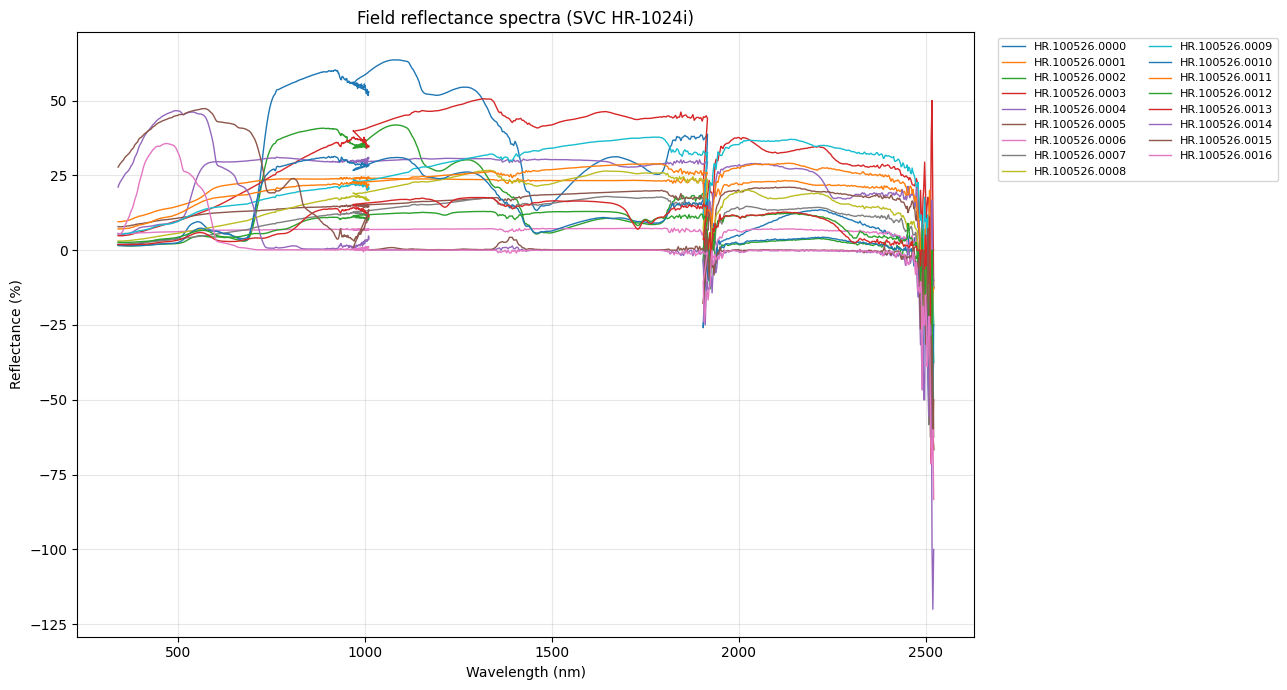

In [2]:
fig, ax = plt.subplots(figsize=(13, 7))
for path in sig_files:
    x, y = parse_sig(path)
    ax.plot(x, y, linewidth=1.0, label=path.stem)

ax.set_title("Field reflectance spectra (SVC HR-1024i)")
ax.set_xlabel("Wavelength (nm)")
ax.set_ylabel("Reflectance (%)")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [3]:
# Optional: save the figure to a PNG file
fig.savefig("my_spectra.png", dpi=300, bbox_inches="tight")
print("Saved my_spectra.png")

Saved my_spectra.png


## Required (14 pts) — When using the 25° foreoptic, your measurement footprint is about half the height of the measurement. Explain why.

         device
           /|\
          / | \
         /12.5°\       full cone angle = 25°
        /   |   \      each half = 12.5°
       /    h    \
      /     |     \
     /______|______\   ground
     |<-r->|
     |<---- d ---->|

footprint diameter = 2*r = 2 · *h* · tan(12.5°) ≈ 2 · *h* · 0.22 ≈ 0.44 *h* 

This means the footprint diameter is approximately 44% ≈ 50% of the instrument's height above the target.

## Required (14 pts) — Why did you need to retake the white reference scan periodically instead of just once at the start? What would happen to your data if the sunlight changed and you didn't recalibrate?

We need to retake the white reference periodically because sunlight conditions change over time due to clouds, sun angle, and atmospheric conditions. Since reflectance is calculated by comparing the target measurement with the white reference, changes in sunlight can lead to inaccurate results.

## Required (13 pts) — Compare your darkest surface and your lightest surface (excluding the reference panel). Describe the overall shape of each curve and explain why one reflects so much more than the other across the range.

**Answer.** My darkest surface was the **darker black asphalt (HR.100526.0006)** and my lightest surface was the
**mulchy dirt (HR.100526.0003)**. Averaged over 350–2400 nm (excluding the noisy water-vapor bands), the asphalt
reflects about **7%** and the mulchy dirt about **29%**.

**Shape of each curve.**
- **Darker asphalt:** the curve is almost a flat line near the bottom of the plot. It stays between about 6% and 7%
  from the blue (6.1% at ~475 nm) through the NIR (6.9% at ~850 nm) to the SWIR (7.2% at ~1650 nm), with no clear
  peaks or absorption features.
- **Mulchy dirt:** the curve rises steadily from the blue (~9%) through the red (~19%) and NIR (~32%) to a maximum
  of about 45% around 1650 nm. It has dips near 1450 nm and 1940 nm, where water absorbs light, and then decreases
  to about 34% near 2200 nm.

**Why one reflects so much more.** Asphalt is held together by bitumen, a dark, carbon-rich binder that absorbs
light at almost every wavelength. Very little light is reflected, and because the absorption is about the same
everywhere, the curve is flat. The mulchy dirt is made of dry soil minerals and dry organic material, which scatter
light back instead of absorbing it, and the scattering gets stronger toward the NIR and SWIR. So the dirt reflects
more than the asphalt at every wavelength, and the gap grows at longer wavelengths. This also means the dirt is the
brightest target over the full range even though a light-colored surface like the tan sidewalk (~21% average) looks
brighter to the eye: most of the dirt's extra reflectance is in the NIR and SWIR, which we cannot see.

In [7]:
means = {path.stem: parse_sig(path)[1].mean() for path in sig_files}

for name, m in sorted(means.items(), key=lambda kv: kv[1], reverse=True):
    print(f"{name}: {m:.1f}%")

HR.100526.0003: 29.3%
HR.100526.0000: 25.9%
HR.100526.0004: 24.6%
HR.100526.0009: 23.2%
HR.100526.0011: 21.1%
HR.100526.0001: 20.8%
HR.100526.0002: 14.9%
HR.100526.0005: 14.7%
HR.100526.0008: 14.5%
HR.100526.0015: 13.5%
HR.100526.0010: 12.2%
HR.100526.0007: 9.9%
HR.100526.0013: 8.6%
HR.100526.0014: 8.1%
HR.100526.0012: 7.9%
HR.100526.0006: 5.9%
HR.100526.0016: 3.4%


#### Required (13 pts) — A target that surprised me

*(TODO: pick the target that actually surprised you and adjust this answer.)*

The **[e.g., green grass / red painted surface]** surprised me. Based on its color I expected it to be
brightest in the **[green / red]** part of the spectrum. Instead, its reflectance was much higher in the
**near-infrared (~750–1300 nm)**, about **[X]%**, compared with about **[Y]%** in the visible.

This showed me that visible color only describes a small part (roughly 400–700 nm) of what a surface reflects.
Most of the differences between materials, such as the NIR plateau of leaves or water absorption in the
SWIR, happen at wavelengths our eyes cannot see. Two surfaces that look similar in color can have very
different full spectra, which is why sensors with NIR and SWIR bands can separate materials that look the
same in a normal photo.

#### Required (13 pts) — Live vs. dry vegetation

*(TODO: check these against your own two curves and fill in the numbers.)*

The two curves differ most in **[the NIR, ~750–1300 nm / the red, ~670 nm / the SWIR]**.

- **Red (~670 nm):** live vegetation is very dark here (about **[X]%**) because chlorophyll absorbs red light
  for photosynthesis. Dry vegetation has lost its chlorophyll, so its red reflectance is much higher and it
  looks brown or yellow instead of green.
- **Red edge and NIR (700–1300 nm):** live vegetation shows a sharp jump at ~700 nm to a high NIR plateau
  (about **[Y]%**). This comes from light scattering inside the healthy, water-filled cell structure of the
  leaf. In dry vegetation the cells have collapsed, so the red edge is weak and the NIR is lower.
- **SWIR (1400–2500 nm):** live vegetation has deep dips near ~1450 and ~1940 nm from water in the leaf.
  Dry vegetation has little water, so its SWIR reflectance is higher, and it shows broad features from
  cellulose and lignin around 2100 and 2300 nm.

The physical cause is the loss of chlorophyll, cell structure, and water as the plant dies.

#### Required (13 pts) — Healthy vs. stressed plant spectrum

Based on today's data, a **healthy** plant spectrum has:
- **low reflectance in the blue and red** (chlorophyll absorption) with a small **green peak** at ~550 nm;
- a **steep red edge** around 700 nm leading to a **high NIR plateau**;
- **deep water absorption dips** in the SWIR near ~1450 and ~1940 nm.

A **stressed or dying** plant moves toward the dry-vegetation curve:
- **red reflectance increases** as chlorophyll breaks down;
- the **red edge becomes less steep** and shifts to shorter wavelengths, and **NIR reflectance drops** as
  the leaf's internal structure degrades;
- **SWIR reflectance increases** and the water dips become shallower as the leaf dries out.

The most useful single signal is the **contrast between red and NIR**: it is large for healthy vegetation and
small for stressed vegetation. This is exactly what indices like NDVI measure, (NIR − Red) / (NIR + Red),
which is why the same idea works from the ground, from drones, and from satellites.